In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('course_lead_scoring_2026.csv')

In [3]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [4]:
df.describe()

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,4631.000000,5000.000000,5000.000000,4965.000000,5000.000000
mean,54533.212049,2.089400,4.472600,0.494767,0.576600
std,21245.661710,1.188987,2.435906,0.199431,0.494147
min,12000.000000,0.000000,0.000000,0.010000,0.000000
25%,40458.500000,1.000000,3.000000,0.360000,0.000000
50%,55051.000000,2.000000,4.000000,0.490000,1.000000
75%,71252.500000,3.000000,6.000000,0.630000,1.000000
max,109886.000000,6.000000,13.000000,0.990000,1.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


#### Check if the missing values are presented in the features.  
#### If there are missing values:  
#### For categorical features, replace them with 'NA'  
#### For numerical features, replace with with 0.0  

In [7]:
df['lead_source'] = df['lead_source'].fillna('NA')

In [8]:
df['industry'] = df['industry'].fillna('NA')

In [9]:
df['employment_status'] = df['employment_status'].fillna('NA')

In [10]:
df['location'] = df['location'].fillna('NA')

In [11]:
df['annual_income'] = df['annual_income'].fillna('0.0')

In [12]:
df['lead_score'] = df['lead_score'].fillna('0.0')

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   lead_source               5000 non-null   object
 1   industry                  5000 non-null   object
 2   employment_status         5000 non-null   object
 3   location                  5000 non-null   object
 4   annual_income             5000 non-null   object
 5   number_of_courses_viewed  5000 non-null   int64 
 6   interaction_count         5000 non-null   int64 
 7   lead_score                5000 non-null   object
 8   converted                 5000 non-null   int64 
dtypes: int64(3), object(6)
memory usage: 351.7+ KB


In [14]:
from sklearn.model_selection import train_test_split

In [15]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

## Question 1: ROC AUC feature importance ##

In [18]:
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='object')

In [19]:
from sklearn.metrics import roc_auc_score

features = [
    'lead_score',
    'number_of_courses_viewed',
    'interaction_count',
    'annual_income'
]

for feature in features:
    auc = roc_auc_score(df_train['converted'], df_train[feature])

    if auc < 0.5:
        auc = roc_auc_score(df_train['converted'], -df_train[feature])

    print(f'{feature}: {auc:.4f}')

lead_score: 0.7882
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
annual_income: 0.6082


## Question 2: Training the model ##

In [20]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

# Separate features and target
y_train = df_train['converted'].values
y_val = df_val['converted'].values

del df_train['converted']
del df_val['converted']

# Apply one-hot encoding
dv = DictVectorizer(sparse=False)

train_dict = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)

# Train logistic regression
model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, solver='liblinear')

In [22]:
from sklearn.metrics import roc_auc_score

y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)

print(round(auc, 3))

0.731


## Question 3: Precision and Recall ##

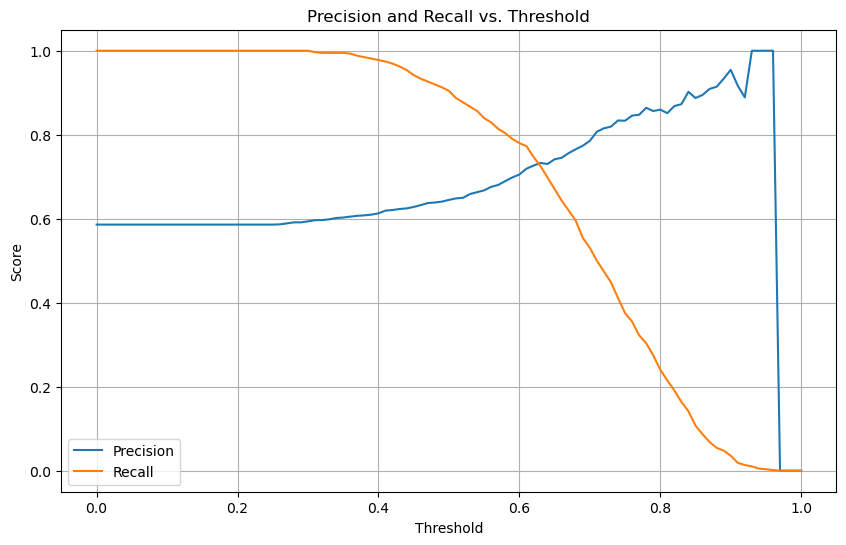

Threshold: 0.63
Precision: 0.733
Recall: 0.725
Absolute difference: 0.0075


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

# Predicted probabilities on the validation dataset
y_pred = model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.0, 1.01, 0.01)
results = []

for t in thresholds:
    y_pred_binary = (y_pred >= t).astype(int)

    precision = precision_score(y_val, y_pred_binary, zero_division=0)
    recall = recall_score(y_val, y_pred_binary, zero_division=0)

    results.append({
        'threshold': t,
        'precision': precision,
        'recall': recall
    })

df_scores = pd.DataFrame(results)

# Plot precision and recall
plt.figure(figsize=(10, 6))
plt.plot(df_scores['threshold'], df_scores['precision'], label='Precision')
plt.plot(df_scores['threshold'], df_scores['recall'], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs. Threshold')
plt.legend()
plt.grid(True)
plt.show()

# Find the intersection (smallest absolute difference)
valid = ~(
    (df_scores['precision'] == 0) &
    (df_scores['recall'] == 0)
)

df_valid = df_scores[valid].copy()
df_valid['difference'] = abs(
    df_valid['precision'] - df_valid['recall']
)

best = df_valid.loc[df_valid['difference'].idxmin()]

print('Threshold:', round(best['threshold'], 2))
print('Precision:', round(best['precision'], 3))
print('Recall:', round(best['recall'], 3))
print('Absolute difference:', round(best['difference'], 4))

## Question 4: F1 score ##

In [24]:
import numpy as np
from sklearn.metrics import precision_score, recall_score

y_pred = model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.0, 1.01, 0.01)
f1_scores = []

for t in thresholds:
    y_pred_binary = (y_pred >= t).astype(int)

    p = precision_score(y_val, y_pred_binary, zero_division=0)
    r = recall_score(y_val, y_pred_binary, zero_division=0)

    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0
    f1_scores.append(f1)

best_idx = np.argmax(f1_scores)

print("Best threshold:", round(thresholds[best_idx], 2))
print("Maximum F1:", round(f1_scores[best_idx], 3))

Best threshold: 0.41
Maximum F1: 0.757


## Question 5: 5-Fold CV ##

In [25]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_fold_train = df_full_train.iloc[train_idx].copy()
    df_fold_val = df_full_train.iloc[val_idx].copy()

    y_train = df_fold_train['converted'].values
    y_val = df_fold_val['converted'].values

    del df_fold_train['converted']
    del df_fold_val['converted']

    dv = DictVectorizer(sparse=True)

    X_train = dv.fit_transform(
        df_fold_train.to_dict(orient='records')
    )
    X_val = dv.transform(
        df_fold_val.to_dict(orient='records')
    )

    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print("AUC scores:", scores)
print("Standard deviation:", np.std(scores))

AUC scores: [np.float64(0.7311571176376184), np.float64(0.7290516458173177), np.float64(0.7372760271856658), np.float64(0.7410985247797393), np.float64(0.7205779764365441)]
Standard deviation: 0.007075942270949419


## Question 6: Hyperparameter Tuning ##

In [26]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

C_values = [0.000001, 0.001, 1]

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for C in C_values:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_fold_train = df_full_train.iloc[train_idx]
        df_fold_val = df_full_train.iloc[val_idx]

        y_train = df_fold_train['converted'].values
        y_val = df_fold_val['converted'].values

        train_dict = df_fold_train.drop(
            columns=['converted']
        ).to_dict(orient='records')

        val_dict = df_fold_val.drop(
            columns=['converted']
        ).to_dict(orient='records')

        dv = DictVectorizer(sparse=True)
        X_train = dv.fit_transform(train_dict)
        X_val = dv.transform(val_dict)

        model = LogisticRegression(
            solver='liblinear',
            C=C,
            max_iter=1000
        )

        model.fit(X_train, y_train)
        y_pred = model.predict_proba(X_val)[:, 1]

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print(
        f'C={C}: mean={np.mean(scores):.3f}, '
        f'std={np.std(scores):.3f}'
    )

C=1e-06: mean=0.617, std=0.019
C=0.001: mean=0.750, std=0.010
C=1: mean=0.732, std=0.007
